# Customer Churn Prediction

End-to-end binary classification project: predict whether a telecom customer is likely to **churn** (leave the company) or stay.

> This notebook is a rebuild of the project I developed during my Machine Learning internship at NexAfrica, recreated from scratch using the public Telco Customer Churn dataset.

**Workflow:** Business Understanding → Data Collection → Data Understanding → Data Cleaning → EDA → Feature Engineering → Preprocessing → Modeling → Evaluation → Class Imbalance → Tuning → Final Model → Feature Importance → Business Insights → Recommendations

_Status: sections 1-4 (Week 1) are complete. The remaining sections are added in later weeks._

## 1. Business Understanding

**What is customer churn?**
Churn happens when a customer stops using a company's service. In a telecom company it means a customer cancels their plan or does not renew.

**Why does it matter?**
It is generally cheaper to keep an existing customer than to acquire a new one. A high churn rate reduces recurring revenue, so even a small improvement in retention can have a large financial impact.

**Goal of the model**
Predict, from demographic, account, service and billing information, whether a customer is likely to churn.

**How can predicting churn help?**
The company can identify high-risk customers *before* they leave and act on them: retention offers, contract upgrades, proactive support or loyalty programs, focusing the budget where it matters most.

**Problem statement**
> The objective of this project is to develop a Machine Learning classification model that predicts whether a customer is likely to churn based on demographic information, account details, subscription information, service usage, contract type, tenure, and billing information.

- **Problem type:** supervised learning, binary classification
- **Target variable:** `Churn` (Yes / No)

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# Make the project's src/ package importable from the notebook
sys.path.append(str(Path.cwd().parent / "src"))

from churn.config import PROCESSED_DATA_PATH, TARGET, VISUALS_DIR
from churn.data.cleaning import clean_data, quality_report
from churn.data.loader import describe_structure, load_raw_data, target_distribution

pd.set_option("display.max_columns", None)

## 2. Data Collection

The data comes from the public **Telco Customer Churn** dataset (IBM sample data, also available on Kaggle): one row per customer of a fictional telecom company. The raw file is stored unmodified in `data/raw_data/telco_churn.csv`.

In [2]:
df_raw = load_raw_data()
describe_structure(df_raw)

Rows:    7,043
Columns: 21

Column names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Data types:
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object


In [3]:
df_raw.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 3. Data Understanding

A description of every variable is available in [`docs/data_dictionary.md`](../docs/data_dictionary.md).

- **Target variable:** `Churn`
- **Identifier:** `customerID` (unique per customer, not used as a predictor)
- **Features:** the other 19 columns: demographics, services, contract, billing and tenure

In [4]:
df_raw.describe().round(2)

,SeniorCitizen,tenure,MonthlyCharges
count,7043.00,7043.00,7043.00
mean,0.16,32.37,64.76
std,0.37,24.56,30.09
min,0.00,0.00,18.25
25%,0.00,9.00,35.50
50%,0.00,29.00,70.35
75%,0.00,55.00,89.85
max,1.00,72.00,118.75


In [5]:
df_raw.select_dtypes(include="object").nunique().sort_values()

Churn                  2
gender                 2
Partner                2
Dependents             2
PhoneService           2
PaperlessBilling       2
Contract               3
StreamingMovies        3
StreamingTV            3
TechSupport            3
OnlineBackup           3
OnlineSecurity         3
InternetService        3
MultipleLines          3
DeviceProtection       3
PaymentMethod          4
TotalCharges        6531
customerID          7043
dtype: int64

## 4. Data Cleaning

### 4.1 Missing values and blank strings

In [6]:
quality_report(df_raw)

,dtype,missing,blank_strings,unique_values
Churn,object,0,0,2
Contract,object,0,0,3
Dependents,object,0,0,2
DeviceProtection,object,0,0,3
InternetService,object,0,0,3
MonthlyCharges,float64,0,0,1585
MultipleLines,object,0,0,3
OnlineBackup,object,0,0,3
OnlineSecurity,object,0,0,3
PaperlessBilling,object,0,0,2


There are no `NaN` values, but **`TotalCharges` is stored as text (`object`)** even though it should be numeric. The reason is hidden in blank strings:

In [7]:
blank_total = df_raw[df_raw["TotalCharges"].str.strip() == ""]
blank_total[["customerID", "tenure", "MonthlyCharges", "TotalCharges"]]

,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,
753,3115-CZMZD,0,20.25,
936,5709-LVOEQ,0,80.85,
1082,4367-NUYAO,0,25.75,
1340,1371-DWPAZ,0,56.05,
3331,7644-OMVMY,0,19.85,
3826,3213-VVOLG,0,25.35,
4380,2520-SGTTA,0,20.00,
5218,2923-ARZLG,0,19.70,
6670,4075-WKNIU,0,73.35,


There are **11 blank values** and all of them belong to customers with `tenure = 0`: new customers who have not been billed yet. The correct value for them is `0`, so they are filled with `0` rather than dropped.

### 4.2 Duplicate records

In [8]:
print(f"Duplicate rows:        {df_raw.duplicated().sum()}")
print(f"Duplicate customerIDs: {df_raw['customerID'].duplicated().sum()}")

Duplicate rows:        0
Duplicate customerIDs: 0


No duplicate rows or duplicate customers.

### 4.3 Inconsistent values in categorical variables

In [9]:
for col in df_raw.select_dtypes(include="object").columns.drop(["customerID", "TotalCharges"]):
    print(f"{col:18s} {sorted(df_raw[col].unique())}")

gender             ['Female', 'Male']
Partner            ['No', 'Yes']
Dependents         ['No', 'Yes']
PhoneService       ['No', 'Yes']
MultipleLines      ['No', 'No phone service', 'Yes']
InternetService    ['DSL', 'Fiber optic', 'No']
OnlineSecurity     ['No', 'No internet service', 'Yes']
OnlineBackup       ['No', 'No internet service', 'Yes']
DeviceProtection   ['No', 'No internet service', 'Yes']
TechSupport        ['No', 'No internet service', 'Yes']
StreamingTV        ['No', 'No internet service', 'Yes']
StreamingMovies    ['No', 'No internet service', 'Yes']
Contract           ['Month-to-month', 'One year', 'Two year']
PaperlessBilling   ['No', 'Yes']
PaymentMethod      ['Bank transfer (automatic)', 'Credit card (automatic)', 'Electronic check', 'Mailed check']
Churn              ['No', 'Yes']


No spelling mistakes, capitalization problems or stray spaces. There are, however, three consistency issues:

1. `SeniorCitizen` is encoded as `0/1` while every other binary column uses `Yes/No`.
2. Six add-on columns (`OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport`, `StreamingTV`, `StreamingMovies`) contain the category `No internet service`, which duplicates the information already in `InternetService`.
3. `MultipleLines` contains `No phone service`, which duplicates `PhoneService`.

### 4.4 Applying the cleaning
The logic lives in `src/churn/data/cleaning.py` (function `clean_data`), so it is reusable outside the notebook:

1. Strip whitespace in text columns
2. Drop duplicate rows / customers
3. Convert `TotalCharges` to numeric (blank → `0` for customers with `tenure = 0`)
4. Convert `SeniorCitizen` from `0/1` to `No/Yes`
5. Merge `No internet service` and `No phone service` into `No`

In [10]:
df = clean_data(df_raw)
quality_report(df)

,dtype,missing,blank_strings,unique_values
Churn,object,0,0,2
Contract,object,0,0,3
Dependents,object,0,0,2
DeviceProtection,object,0,0,2
InternetService,object,0,0,3
MonthlyCharges,float64,0,0,1585
MultipleLines,object,0,0,2
OnlineBackup,object,0,0,2
OnlineSecurity,object,0,0,2
PaperlessBilling,object,0,0,2


In [11]:
PROCESSED_DATA_PATH.parent.mkdir(parents=True, exist_ok=True)
df.to_csv(PROCESSED_DATA_PATH, index=False)
print(f"Saved cleaned dataset: {df.shape[0]:,} rows x {df.shape[1]} columns")

Saved cleaned dataset: 7,043 rows x 21 columns


### 4.5 Target variable distribution

In [12]:
dist = target_distribution(df)
dist

,count,percentage
Churn,,
No,5174,73.46
Yes,1869,26.54


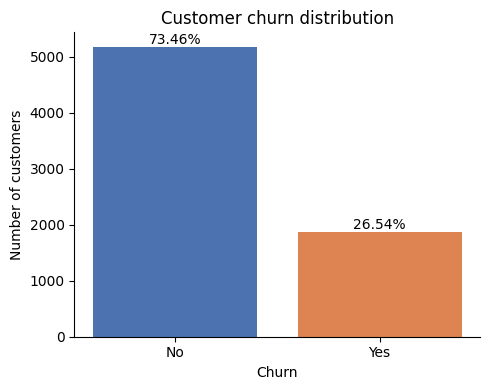

In [13]:
VISUALS_DIR.mkdir(exist_ok=True)

fig, ax = plt.subplots(figsize=(5, 4))
bars = ax.bar(dist.index, dist["count"], color=["#4C72B0", "#DD8452"])
for bar, pct in zip(bars, dist["percentage"]):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 50, f"{pct}%", ha="center")
ax.set_title("Customer churn distribution")
ax.set_xlabel("Churn")
ax.set_ylabel("Number of customers")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(VISUALS_DIR / "target_distribution.png", dpi=150)
plt.show()

**Observations**

- **26.54%** of customers churned (1,869) versus **73.46%** who stayed (5,174), roughly a 2.8 : 1 ratio. The dataset is **moderately imbalanced**.
- A model that always predicts "No churn" would already reach about 73% accuracy without detecting a single churner. **Accuracy alone is therefore misleading**, and models will be compared using Precision, Recall, F1-score and ROC-AUC.
- The train/test split will be **stratified** to keep this class proportion, and imbalance-handling techniques will be tested in Week 4.

---
# Week 2: Exploratory Data Analysis and Feature Engineering

## 5. Exploratory Data Analysis

Goal: understand **which customers churn and why**, using the cleaned dataset.

In [14]:
import seaborn as sns
from scipy.stats import chi2_contingency

from churn.config import FEATURES_DATA_PATH, ML_READY_DATA_PATH
from churn.features.engineering import ENGINEERED_FEATURES, add_features
from churn.features.preprocessing import (
    LOW_SIGNAL_FEATURES,
    NUMERIC_FEATURES,
    encode_features,
    scale_numeric,
    select_features,
    split_features_target,
)
from churn.visualization.eda import CHURN_COLORS, churn_rate_by, plot_churn_rate, save_fig

sns.set_theme(style="whitegrid")
NUMERIC_COLUMNS = ["tenure", "MonthlyCharges", "TotalCharges"]
overall_churn = df["Churn"].eq("Yes").mean() * 100

### 5.1 Descriptive statistics

In [15]:
df[NUMERIC_COLUMNS].describe().round(2)

,tenure,MonthlyCharges,TotalCharges
count,7043.00,7043.00,7043.00
mean,32.37,64.76,2279.73
std,24.56,30.09,2266.79
min,0.00,18.25,0.00
25%,9.00,35.50,398.55
50%,29.00,70.35,1394.55
75%,55.00,89.85,3786.60
max,72.00,118.75,8684.80


In [16]:
df.groupby("Churn")[NUMERIC_COLUMNS].agg(["mean", "median"]).round(2)

tenure        MonthlyCharges        TotalCharges         
        mean median           mean median         mean   median
Churn                                                          
No     37.57   38.0          61.27  64.43      2549.91  1679.52
Yes    17.98   10.0          74.44  79.65      1531.80   703.55

In [17]:
df.drop(columns="customerID").describe(include="object").T

,count,unique,top,freq
gender,7043,2,Male,3555
SeniorCitizen,7043,2,No,5901
Partner,7043,2,No,3641
Dependents,7043,2,No,4933
PhoneService,7043,2,Yes,6361
MultipleLines,7043,2,No,4072
InternetService,7043,3,Fiber optic,3096
OnlineSecurity,7043,2,No,5024
OnlineBackup,7043,2,No,4614
DeviceProtection,7043,2,No,4621


- Customers stay **32 months on average** (median 29), with a wide range from 0 to 72 months.
- Monthly charges go from **\$18.25 to \$118.75** (mean \$64.76). `TotalCharges` is right-skewed because it accumulates over time.
- Customers who churned have a **much lower median tenure (10 vs 38 months)** and a **higher median monthly charge (\$79.65 vs \$64.43)**.

### 5.2 Distribution of numerical variables

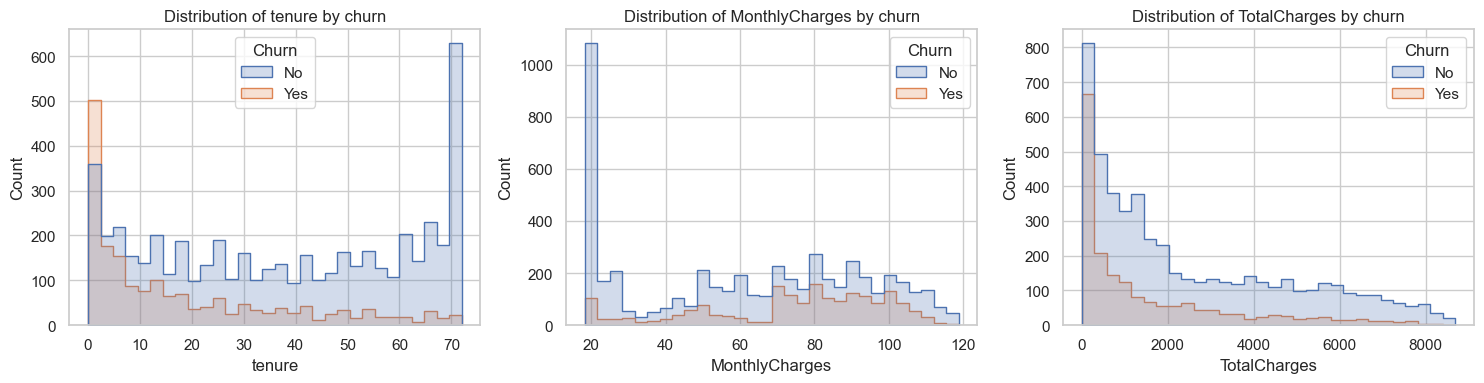

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, NUMERIC_COLUMNS):
    sns.histplot(data=df, x=col, hue="Churn", bins=30, palette=CHURN_COLORS, element="step", ax=ax)
    ax.set_title(f"Distribution of {col} by churn")
fig.tight_layout()
save_fig(fig, "numeric_distributions.png")
plt.show()

- **Tenure:** churners are concentrated in the first months, while non-churners have a second peak at 70+ months (long-term loyal customers).
- **MonthlyCharges:** the cheapest plans (about \$20) have very little churn; churn is more frequent above \$70.
- **TotalCharges:** churners are concentrated at low values, a direct consequence of their short tenure.

### 5.3 Outlier detection

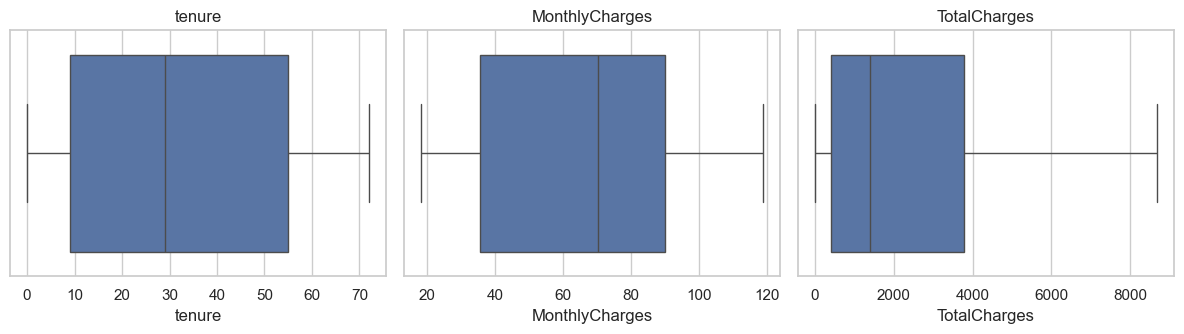

,outliers (IQR rule)
tenure,0
MonthlyCharges,0
TotalCharges,0


In [19]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, col in zip(axes, NUMERIC_COLUMNS):
    sns.boxplot(data=df, x=col, color="#4C72B0", ax=ax)
    ax.set_title(col)
fig.tight_layout()
save_fig(fig, "outliers_boxplots.png")
plt.show()

def count_iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum())

df[NUMERIC_COLUMNS].apply(count_iqr_outliers).rename("outliers (IQR rule)").to_frame()

The IQR rule finds **no outliers** in any numerical variable, and every value is realistic (tenure between 0 and 72 months, charges within the plan price range). **No outlier handling is needed**, so no rows are removed.

### 5.4 Churn by contract, payment method, internet service and billing

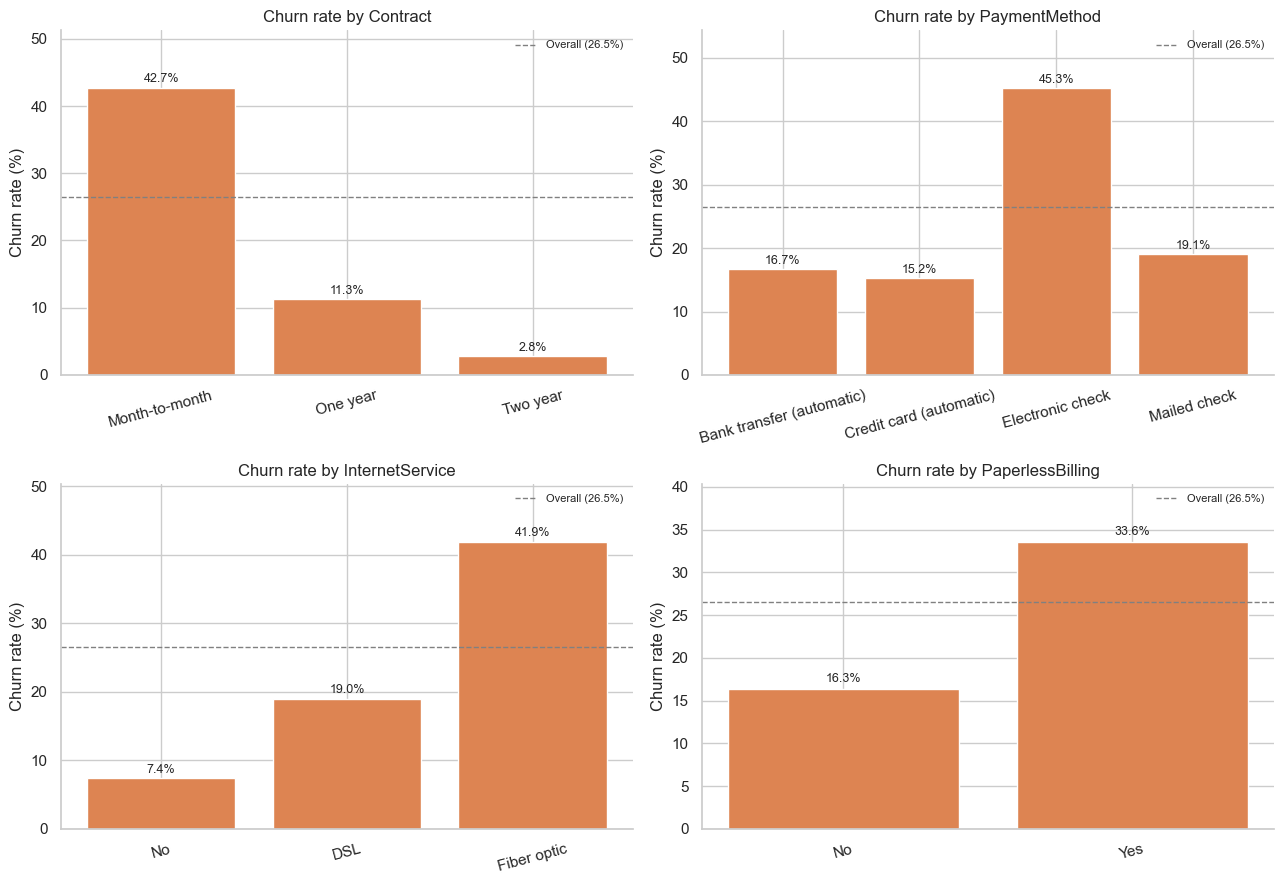

In [20]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
plot_churn_rate(df, "Contract", ax=axes[0, 0], order=["Month-to-month", "One year", "Two year"])
plot_churn_rate(df, "PaymentMethod", ax=axes[0, 1])
plot_churn_rate(df, "InternetService", ax=axes[1, 0], order=["No", "DSL", "Fiber optic"])
plot_churn_rate(df, "PaperlessBilling", ax=axes[1, 1], order=["No", "Yes"])
fig.tight_layout()
save_fig(fig, "churn_analysis.png")
plt.show()

In [21]:
pd.concat(
    {col: churn_rate_by(df, col) for col in ["Contract", "PaymentMethod", "InternetService"]}
).rename_axis(["variable", "category"])

customers  churn_rate
variable        category                                        
Contract        Month-to-month                  3875       42.71
                One year                        1473       11.27
                Two year                        1695        2.83
PaymentMethod   Bank transfer (automatic)       1544       16.71
                Credit card (automatic)         1522       15.24
                Electronic check                2365       45.29
                Mailed check                    1612       19.11
InternetService DSL                             2421       18.96
                Fiber optic                     3096       41.89
                No                              1526        7.40

### 5.5 Churn by tenure and monthly charges

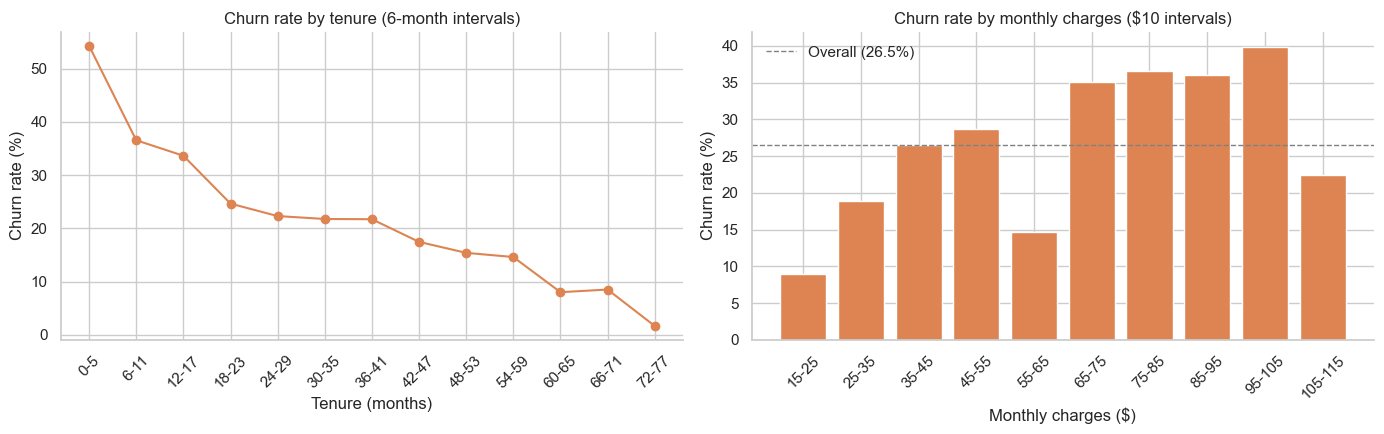

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

tenure_bins = pd.cut(df["tenure"], bins=range(-1, 79, 6))
tenure_rate = df.groupby(tenure_bins, observed=True)["Churn"].apply(lambda s: s.eq("Yes").mean() * 100)
axes[0].plot(range(len(tenure_rate)), tenure_rate.values, marker="o", color=CHURN_COLORS["Yes"])
axes[0].set_xticks(range(len(tenure_rate)))
axes[0].set_xticklabels([f"{int(i.left) + 1}-{int(i.right)}" for i in tenure_rate.index], rotation=45)
axes[0].set_title("Churn rate by tenure (6-month intervals)")
axes[0].set_xlabel("Tenure (months)")
axes[0].set_ylabel("Churn rate (%)")

charge_bins = pd.cut(df["MonthlyCharges"], bins=range(15, 125, 10))
charge_rate = df.groupby(charge_bins, observed=True)["Churn"].apply(lambda s: s.eq("Yes").mean() * 100)
axes[1].bar(range(len(charge_rate)), charge_rate.values, color=CHURN_COLORS["Yes"])
axes[1].set_xticks(range(len(charge_rate)))
axes[1].set_xticklabels([f"{int(i.left)}-{int(i.right)}" for i in charge_rate.index], rotation=45)
axes[1].axhline(overall_churn, color="gray", linestyle="--", linewidth=1, label=f"Overall ({overall_churn:.1f}%)")
axes[1].set_title("Churn rate by monthly charges (\$10 intervals)")
axes[1].set_xlabel("Monthly charges (\$)")
axes[1].set_ylabel("Churn rate (%)")
axes[1].legend(frameon=False)

for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
save_fig(fig, "churn_by_tenure_and_charges.png")
plt.show()

### 5.6 Churn by customer demographics

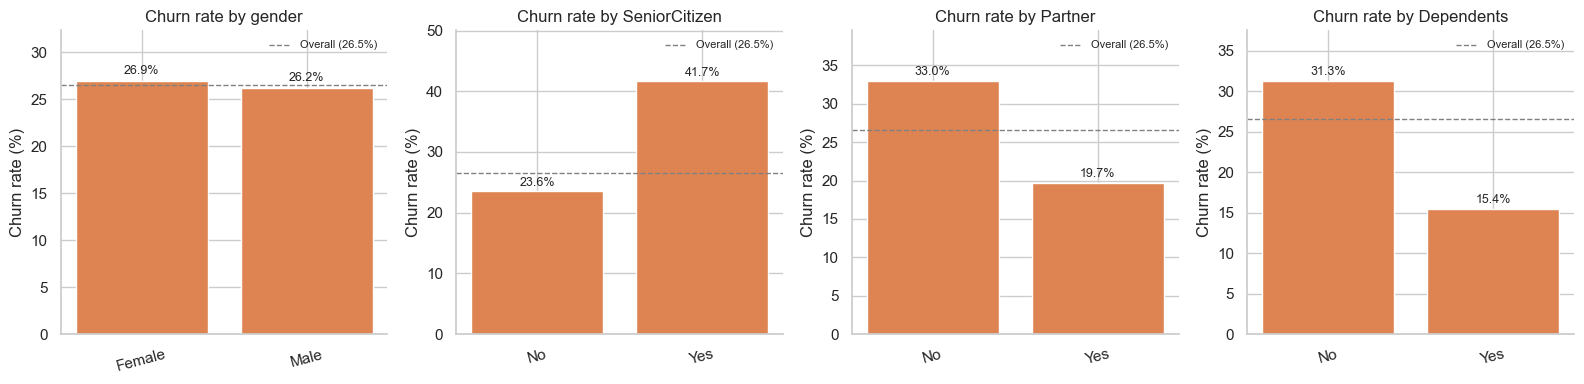

In [23]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, ["gender", "SeniorCitizen", "Partner", "Dependents"]):
    plot_churn_rate(df, col, ax=ax)
fig.tight_layout()
save_fig(fig, "churn_by_demographics.png")
plt.show()

### 5.7 Churn by subscribed services

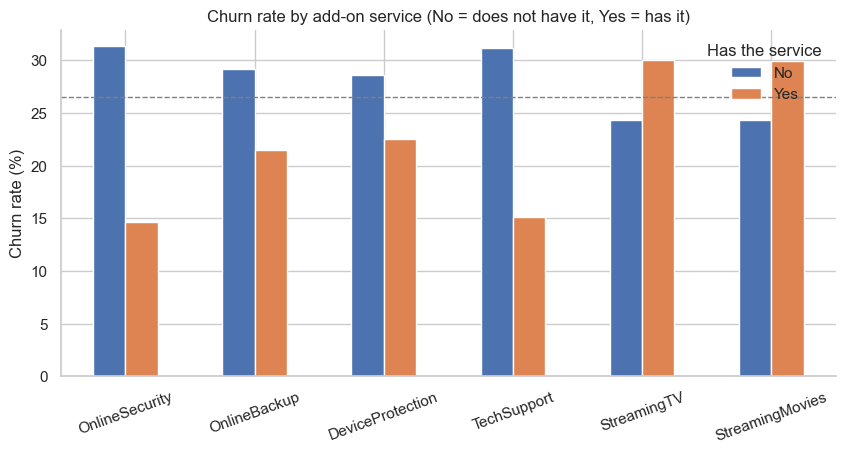

,No,Yes
OnlineSecurity,31.33,14.61
OnlineBackup,29.17,21.53
DeviceProtection,28.65,22.50
TechSupport,31.19,15.17
StreamingTV,24.33,30.07
StreamingMovies,24.38,29.94


In [24]:
service_columns = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]
service_rates = pd.DataFrame(
    {col: churn_rate_by(df, col)["churn_rate"] for col in service_columns}
).T[["No", "Yes"]]

ax = service_rates.plot(kind="bar", figsize=(10, 4.5), color=[CHURN_COLORS["No"], CHURN_COLORS["Yes"]])
ax.axhline(overall_churn, color="gray", linestyle="--", linewidth=1)
ax.set_title("Churn rate by add-on service (No = does not have it, Yes = has it)")
ax.set_ylabel("Churn rate (%)")
ax.tick_params(axis="x", labelrotation=20)
ax.legend(title="Has the service", frameon=False)
ax.spines[["top", "right"]].set_visible(False)
save_fig(ax.figure, "churn_by_services.png")
plt.show()
service_rates

### 5.8 Correlations

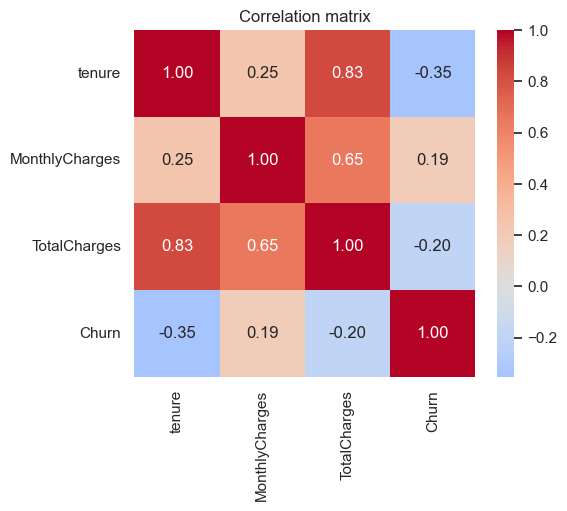

In [25]:
corr_df = df[NUMERIC_COLUMNS].assign(Churn=df["Churn"].eq("Yes").astype(int))
fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(corr_df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlation matrix")
save_fig(fig, "correlation_heatmap.png")
plt.show()

- `tenure` and `TotalCharges` are strongly correlated (**0.83**), as expected since the total is roughly tenure x monthly charge. This redundancy matters for Logistic Regression.
- `tenure` has the strongest (negative) relation with churn (**-0.35**); `MonthlyCharges` has a weaker positive one (**0.19**).

### 5.9 Key insights

1. **Contract type is the strongest driver.** Month-to-month customers churn **42.7%**, versus 11.3% (one year) and only 2.8% (two year).
2. **New customers churn the most.** Churn is 47.4% in the first year and falls steadily with tenure. Churners have a median tenure of 10 months versus 38 for loyal customers.
3. **Higher bills are linked to more churn.** Customers paying \$70-\$90 per month churn about 38%, versus about 11% for those paying under \$35.
4. **Payment method matters.** Electronic check users churn **45.3%**, around three times more than customers on automatic payments (bank transfer 16.7%, credit card 15.2%).
5. **Fiber optic customers churn far more than the rest.** 41.9% versus 19.0% for DSL and 7.4% for customers without internet. Fiber is also the most expensive plan, which points to a price or quality problem.
6. **Support and security services protect against churn.** Customers with Online Security or Tech Support churn about 15%, versus about 31% for those without them.
7. **Demographics:** senior citizens (41.7% vs 23.6%) and customers without partner (33.0% vs 19.7%) or dependents (31.3% vs 15.5%) churn more, while **gender has no effect** (26.9% vs 26.2%).
8. **Paperless billing** is associated with higher churn (33.6% vs 16.3%).

## 6. Feature Engineering

New features created from the cleaned data (implemented in `src/churn/features/engineering.py` and documented in [`docs/feature_engineering.md`](../docs/feature_engineering.md)):

| New feature | How it was created | Why it may help predict churn |
|---|---|---|
| `tenure_group` | `tenure` binned into 0-12, 13-24, 25-48 and 49-72 months | Churn follows a clear lifecycle: it is highest in the first year. Groups capture this non-linear effect. |
| `num_services` | Count of subscribed services: phone, multiple lines, internet and the six add-ons | Customers with more services are more tied to the company, but also pay more. |
| `num_protection_services` | Count of `OnlineSecurity`, `OnlineBackup`, `DeviceProtection` and `TechSupport` | Protection and support services showed lower churn in the EDA. |
| `has_streaming` | `Yes` if the customer has `StreamingTV` or `StreamingMovies` | Summarizes the entertainment services in a single indicator. |
| `spending_category` | `MonthlyCharges` binned into Low (up to \$35), Medium (\$35-\$70) and High (above \$70) | Churn rises with the monthly bill, and bands capture it as customer value groups. |
| `auto_payment` | `Yes` if the payment method is bank transfer or credit card (automatic) | Automatic payment needs no monthly action, so those customers churn much less. |
| `avg_monthly_spend` | `TotalCharges / tenure` (current `MonthlyCharges` when tenure is 0) | Reveals customers whose current bill differs from what they historically paid. |

In [26]:
df_fe = add_features(df)
df_fe[["customerID", "tenure", "MonthlyCharges", *ENGINEERED_FEATURES]].head(8)

,customerID,tenure,MonthlyCharges,tenure_group,num_services,num_protection_services,has_streaming,spending_category,auto_payment,avg_monthly_spend
0,7590-VHVEG,1,29.85,0-12 months,2,1,No,Low,No,29.85
1,5575-GNVDE,34,56.95,25-48 months,4,2,No,Medium,No,55.57
2,3668-QPYBK,2,53.85,0-12 months,4,2,No,Medium,No,54.08
3,7795-CFOCW,45,42.30,25-48 months,4,3,No,Medium,Yes,40.91
4,9237-HQITU,2,70.70,0-12 months,2,0,No,High,No,75.82
5,9305-CDSKC,8,99.65,0-12 months,6,1,Yes,High,No,102.56
6,1452-KIOVK,22,89.10,13-24 months,5,1,Yes,High,Yes,88.61
7,6713-OKOMC,10,29.75,0-12 months,2,1,No,Low,No,30.19


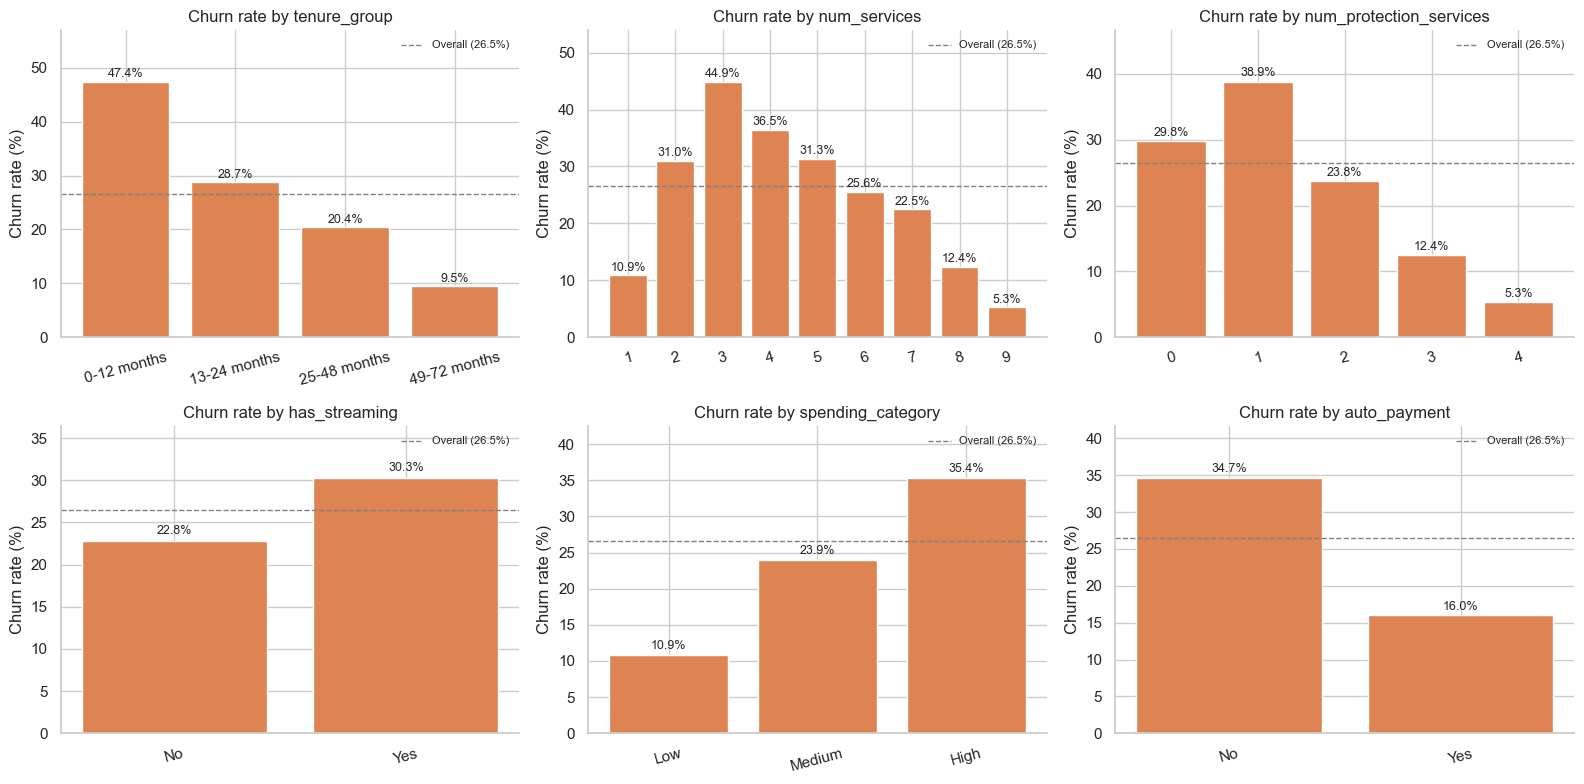

In [27]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
plot_churn_rate(df_fe, "tenure_group", ax=axes[0, 0])
plot_churn_rate(df_fe, "num_services", ax=axes[0, 1])
plot_churn_rate(df_fe, "num_protection_services", ax=axes[0, 2])
plot_churn_rate(df_fe, "has_streaming", ax=axes[1, 0], order=["No", "Yes"])
plot_churn_rate(df_fe, "spending_category", ax=axes[1, 1], order=["Low", "Medium", "High"])
plot_churn_rate(df_fe, "auto_payment", ax=axes[1, 2], order=["No", "Yes"])
fig.tight_layout()
save_fig(fig, "engineered_features.png")
plt.show()

- `tenure_group`: churn drops from **47.4%** (0-12 months) to **9.5%** (49-72 months).
- `num_protection_services`: churn falls from 38.9% (1 service) to **5.3%** (all 4), confirming that these services keep customers.
- `spending_category`: **High** spenders churn 35.4% versus 10.9% for **Low** spenders.
- `auto_payment`: customers without automatic payment churn **34.7%** versus 16.0% with it.
- `num_services` is not linear: customers with a single service (basically phone only) churn little (10.9%), churn peaks at 3 services (44.9%, typically fiber without add-ons) and falls again with many services (5.3% with 9).

## 7. Data Preprocessing

### 7.1 Feature selection

A chi-square test measures whether each categorical feature is related to churn. The null hypothesis is that the feature and churn are independent; a p-value above 0.05 means no evidence of a relation.

In [28]:
categorical_cols = df_fe.select_dtypes(include="object").columns.drop(["customerID", "Churn"])
chi2_results = pd.DataFrame(
    {col: chi2_contingency(pd.crosstab(df_fe[col], df_fe["Churn"]))[1] for col in categorical_cols},
    index=["p_value"],
).T.sort_values("p_value")
chi2_results["related_to_churn"] = chi2_results["p_value"] < 0.05
chi2_results.round(4)

,p_value,related_to_churn
Contract,0.0000,True
tenure_group,0.0000,True
InternetService,0.0000,True
PaymentMethod,0.0000,True
spending_category,0.0000,True
auto_payment,0.0000,True
PaperlessBilling,0.0000,True
OnlineSecurity,0.0000,True
TechSupport,0.0000,True
Dependents,0.0000,True


Only **`gender`** (p = 0.49) and **`PhoneService`** (p = 0.34) show no relation with churn, so they are **dropped**. Other decisions:

- `customerID` is an identifier, not a predictor: **dropped**.
- `TotalCharges` is highly correlated with `tenure` (0.83) but it is **kept**, since tree-based models are not affected and the effect on Logistic Regression will be checked in Week 3.
- The original `tenure` and `MonthlyCharges` are kept next to their engineered groups because each carries different information (exact value vs. band).

In [29]:
assert set(chi2_results.index[~chi2_results["related_to_churn"]]) == set(LOW_SIGNAL_FEATURES)

df_selected = select_features(df_fe)
print(f"Features kept: {df_selected.shape[1] - 1} (plus the target)")

Features kept: 24 (plus the target)


### 7.2 Encoding categorical variables

- **Binary columns (Yes/No)** and the target become `1/0`.
- **Multi-category columns** (`InternetService`, `Contract`, `PaymentMethod`, `tenure_group`, `spending_category`) are one-hot encoded, dropping the first level to avoid redundant columns.

In [30]:
df_ml = encode_features(df_selected)
print(f"Shape: {df_ml.shape} | missing values: {df_ml.isna().sum().sum()}")
df_ml.dtypes.value_counts()

Shape: (7043, 32) | missing values: 0


int64      29
float64     3
Name: count, dtype: int64

### 7.3 Scaling numerical features

Numerical variables have very different ranges (`num_protection_services` from 0 to 4, `TotalCharges` up to 8,685). Distance- and gradient-based models such as Logistic Regression and KNN need standardized features, while tree-based models do not.

To avoid **data leakage**, the scaler must be **fitted on the training set only**. Because the train/test split is done in Week 3, the saved dataset is left **unscaled** and `scale_numeric()` (in `src/churn/features/preprocessing.py`) is applied after splitting. The next cell is only a demonstration that it works:

In [31]:
X, y = split_features_target(df_ml)
X_demo_train, X_demo_test, _ = scale_numeric(X.iloc[:5000], X.iloc[5000:])
X_demo_train[NUMERIC_FEATURES].agg(["mean", "std"]).round(2)

,tenure,MonthlyCharges,TotalCharges,avg_monthly_spend,num_services,num_protection_services
mean,0.0,0.0,0.0,0.0,0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0,1.0


### 7.4 Separate features and target, and save the machine-learning-ready dataset

In [32]:
df_fe.to_csv(FEATURES_DATA_PATH, index=False)
df_ml.to_csv(ML_READY_DATA_PATH, index=False)

print(f"Feature-engineered dataset: {df_fe.shape[0]:,} rows x {df_fe.shape[1]} columns -> {FEATURES_DATA_PATH.name}")
print(f"ML-ready dataset:           {df_ml.shape[0]:,} rows x {df_ml.shape[1]} columns -> {ML_READY_DATA_PATH.name}")
print(f"\nX: {X.shape} | y: {y.shape} | churn rate in y: {y.mean():.2%}")
print(f"\nFeatures used for modeling ({X.shape[1]}):")
print(list(X.columns))

Feature-engineered dataset: 7,043 rows x 28 columns -> telco_churn_features.csv
ML-ready dataset:           7,043 rows x 32 columns -> telco_churn_ml_ready.csv

X: (7043, 31) | y: (7043,) | churn rate in y: 26.54%

Features used for modeling (31):
['SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'MultipleLines', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'PaperlessBilling', 'MonthlyCharges', 'TotalCharges', 'num_services', 'num_protection_services', 'has_streaming', 'auto_payment', 'avg_monthly_spend', 'InternetService_Fiber optic', 'InternetService_No', 'Contract_One year', 'Contract_Two year', 'PaymentMethod_Credit card (automatic)', 'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check', 'tenure_group_13-24 months', 'tenure_group_25-48 months', 'tenure_group_49-72 months', 'spending_category_Low', 'spending_category_Medium']


**Week 2 summary**

- 10+ visualizations saved in `visuals/` and 8 documented insights.
- 7 engineered features and 2 low-signal features removed.
- `telco_churn_ml_ready.csv`: fully numeric, no missing values, ready for the train/test split.

---
# Week 3: Machine Learning Model Development

## 8. Model Development

### 8.1 Train/test split

The models are trained on one part of the data and evaluated on a part they have never seen, which simulates new customers. The split is:

- **80% training / 20% testing.**
- **Stratified** by `Churn`, so both sets keep the same 26.5% churn rate (important with imbalanced classes).
- Done **before** any scaling or fitting, so no information from the test set leaks into training.
- Fixed `random_state` so the results are reproducible.

In [33]:
from churn.data.loader import load_ml_ready_data
from churn.modeling.evaluate import METRICS, compare_models, confusion_matrix_table, evaluate_models
from churn.modeling.split import save_split, split_data
from churn.modeling.train import XGBOOST_AVAILABLE, get_models, train_models
from churn.visualization.model_plots import plot_confusion_matrices, plot_model_comparison, plot_roc_curves

df_model = load_ml_ready_data()
X_train, X_test, y_train, y_test = split_data(df_model)
save_split(X_train, X_test, y_train, y_test)

pd.DataFrame(
    {
        "rows": [len(X_train), len(X_test)],
        "features": [X_train.shape[1], X_test.shape[1]],
        "churn rate": [f"{y_train.mean():.2%}", f"{y_test.mean():.2%}"],
    },
    index=["Training set", "Testing set"],
)

XGBoost is not available (is libomp installed?). Using sklearn's Gradient Boosting instead.


,rows,features,churn rate
Training set,5634,31,26.54%
Testing set,1409,31,26.54%


The training and testing sets are saved as `data/processed_data/train.csv` and `test.csv`, and both keep the 26.54% churn rate.

### 8.2 Models

Four classification models are trained with simple, untuned settings. Tuning and class-imbalance handling are left for Week 4, so these results are the starting point to improve.

| Model | Role | Notes |
|---|---|---|
| **Logistic Regression** | Baseline | Simple and interpretable. Numeric features are standardized inside its pipeline, fitted on the training set only. |
| **Decision Tree** | Additional model | `max_depth=5` to keep it readable and avoid memorizing the training data. |
| **Random Forest** | Additional model | 200 trees; an ensemble that usually beats a single tree. |
| **XGBoost** | Additional model | Gradient boosting. If XGBoost cannot be loaded on the machine, sklearn's *Gradient Boosting* is used instead (same family of model). |

In [34]:
print("XGBoost available:", XGBOOST_AVAILABLE)
models = get_models()
fitted = train_models(models, X_train, y_train)
list(fitted)

XGBoost available: False


['Logistic Regression', 'Decision Tree', 'Random Forest', 'Gradient Boosting']

## 9. Model Evaluation

### 9.1 What each metric means for churn

Churn is the **positive class**, so the metrics answer these questions:

| Metric | Question it answers | Why it matters here |
|---|---|---|
| **Accuracy** | What share of all predictions is correct? | Misleading: always predicting "stays" already gives about 73%. |
| **Precision** | Of the customers flagged as churners, how many really leave? | Low precision wastes retention offers on customers who would have stayed. |
| **Recall** | Of the customers who really leave, how many did we catch? | Low recall means churners go unnoticed and the company loses them. |
| **F1-score** | Balance between precision and recall | Better summary than accuracy for imbalanced data. |
| **ROC-AUC** | How well does the model rank churners above non-churners, at any threshold? | Independent of the 0.5 threshold; 0.5 is random and 1.0 is perfect. |
| **Confusion matrix** | Counts of true/false positives and negatives | Shows exactly which type of error each model makes. |

### 9.2 Baseline: Logistic Regression

In [35]:
results = evaluate_models(fitted, X_train, y_train, X_test, y_test)

baseline = pd.Series(results["Logistic Regression"]["metrics"], name="Logistic Regression").round(4)
baseline.to_frame()

,Logistic Regression
Accuracy,0.7928
Precision,0.6358
Recall,0.5134
F1-Score,0.5680
ROC-AUC,0.8419


In [36]:
confusion_matrix_table(y_test, results["Logistic Regression"]["y_pred"])

,Predicted: No churn,Predicted: Churn
Actual: No churn,925,110
Actual: Churn,182,192


The baseline reaches about **79% accuracy**, only 6 points above the "always No churn" rule, and its **recall is about 51%**: it detects roughly half of the churners. Precision is about 64%. The ROC-AUC (**0.84**) shows that the model ranks customers well, so the weakness is mostly the default 0.5 threshold on an imbalanced target, which Week 4 addresses.

### 9.3 Model comparison

In [37]:
comparison = compare_models(results)
comparison.round(4).style.highlight_max(axis=0, color="#cfe8cf")

,Accuracy,Precision,Recall,F1-Score,ROC-AUC,Train ROC-AUC
Logistic Regression,0.792800,0.635800,0.513400,0.568000,0.841900,0.851000
Decision Tree,0.788500,0.619500,0.526700,0.569400,0.826800,0.846800
Random Forest,0.788500,0.629300,0.494700,0.553900,0.821000,0.999900
Gradient Boosting,0.792100,0.639200,0.497300,0.559400,0.841800,0.881600


The highlighted cell is the best value in each column. **Train ROC-AUC** is the AUC on the training data: a large gap versus the test ROC-AUC means the model memorized the training set (overfitting).

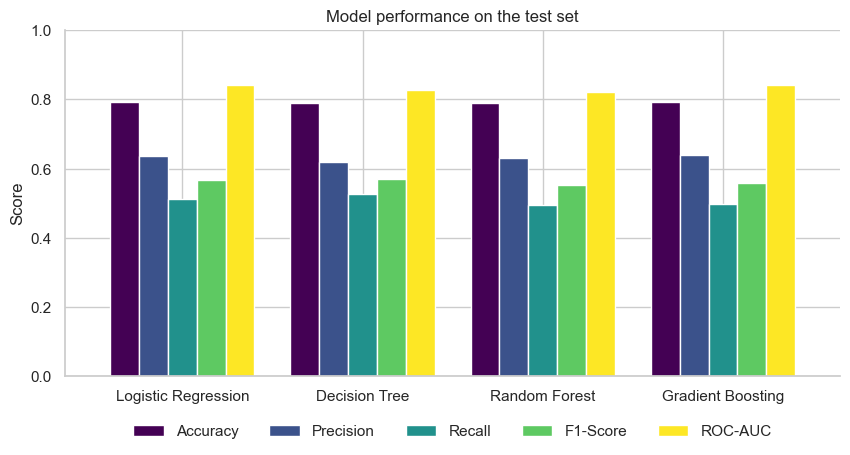

In [38]:
fig = plot_model_comparison(comparison)
save_fig(fig, "model_performance.png")
plt.show()

### 9.4 Confusion matrices

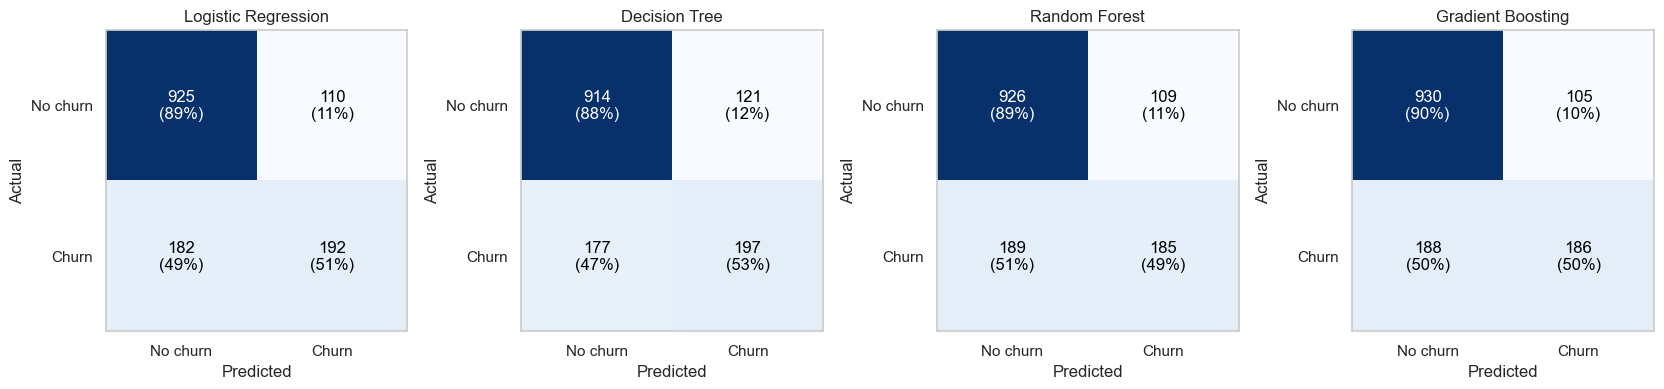

In [39]:
fig = plot_confusion_matrices(results, y_test)
save_fig(fig, "confusion_matrices.png")
plt.show()

Each cell shows the count and the percentage of its row. The bottom-left cell (**false negatives**) contains churners that the model missed: in every model it is around half of the churners.

### 9.5 ROC curves

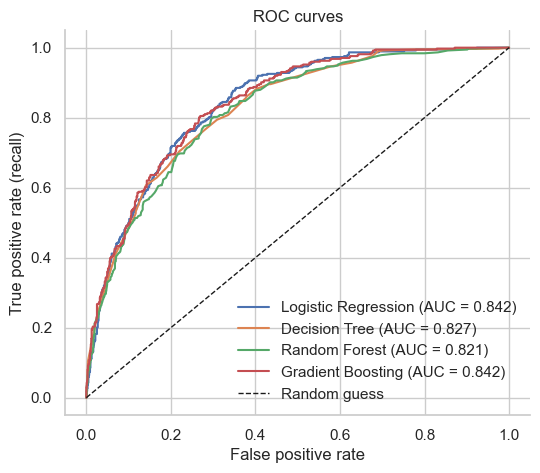

In [40]:
fig = plot_roc_curves(results, y_test)
save_fig(fig, "roc_curves.png")
plt.show()

### 9.6 Initial model selection

Results on the test set (values from the run with sklearn's Gradient Boosting; if XGBoost is installed the last row changes slightly):

| Model | Accuracy | Precision | Recall | F1-Score | ROC-AUC |
|---|---|---|---|---|---|
| Logistic Regression | 0.793 | 0.636 | 0.513 | 0.568 | **0.842** |
| Decision Tree | 0.789 | 0.620 | **0.527** | **0.569** | 0.827 |
| Random Forest | 0.789 | 0.629 | 0.495 | 0.554 | 0.821 |
| Gradient Boosting | 0.792 | **0.639** | 0.497 | 0.559 | 0.842 |

**Observations**

- The four models are **very close** (accuracy 78.9% to 79.3%), so accuracy cannot separate them, as expected with imbalanced data.
- **Random Forest overfits**: its training ROC-AUC is about 1.00 but only 0.82 on the test set. Its default settings need tuning (depth, minimum samples per leaf).
- **Logistic Regression and Gradient Boosting have the best ROC-AUC (0.842)** and a small train/test gap, which means they generalize well.
- **All models detect only about half of the churners (recall 49% to 53%)**. For this business, missing a churner is more expensive than contacting a customer who would have stayed, so recall must improve.

**Initial choice: Logistic Regression.** It ties for the best ROC-AUC and the best accuracy, it does not overfit, and it is the simplest and most interpretable model, so its coefficients will explain what drives churn. Gradient Boosting is the main challenger, and ensemble models usually gain more from tuning, so they will be optimized in Week 4 together with class-imbalance handling (class weights, SMOTE) to raise recall.

**Week 3 summary**

- Stratified 80/20 split saved as `train.csv` and `test.csv`.
- 4 classification models trained and compared with Accuracy, Precision, Recall, F1-score and ROC-AUC.
- Confusion matrices, ROC curves and a comparison chart saved in `visuals/`.
- Main finding: all models reach ~79% accuracy but catch only about half of the churners.

---
# Week 4: Class Imbalance, Cross-Validation and Model Optimization

## 10. Class Imbalance Handling

### 10.1 Is the dataset imbalanced?

In [41]:
from churn.modeling.imbalance import STRATEGIES, improvement_table, run_strategies, strategy_table, build_models
from churn.modeling.tuning import tune_all, tuning_summary
from churn.modeling.validation import cross_validate_models, summarize_cv
from churn.visualization.model_plots import plot_cv_scores, plot_strategy_comparison

counts = y_train.value_counts().rename(index={0: "No churn", 1: "Churn"})
pd.DataFrame({"customers": counts, "percentage": (counts / counts.sum() * 100).round(2)})

,customers,percentage
Churn,,
No churn,4139,73.46
Churn,1495,26.54


Yes: in the training set there are about **2.8 non-churners for every churner** (73.5% vs 26.5%).

**Why this affects the models**

- Most algorithms minimize the *overall* error, so predicting "stays" for almost everyone is already a good deal for them.
- They see far fewer churn examples, so they learn the churn pattern less well.
- The default decision threshold (0.5) is rarely reached for the minority class. We saw the result in Week 3: **accuracy of 79% but only about 50% of churners detected**.

For the business, a missed churner (lost revenue) costs more than a retention offer sent to a customer who would have stayed, so we want a **higher recall** without destroying precision.

### 10.2 Strategies tested

| Strategy | How it works | Why it was selected |
|---|---|---|
| **Class weight** | Mistakes on churners weigh about 2.8 times more during training. No data is changed. | Simplest option, no synthetic data, fast. |
| **SMOTE** (oversampling) | Creates synthetic churners between existing ones until both classes have the same size. | Gives the model more churn examples without repeating rows. |
| **Random undersampling** | Removes random non-churners until both classes have the same size. | Fast, but throws away information. |

Resampling is applied **only to the training data**. It sits inside an `imblearn` Pipeline, so it is also applied only to the training part of each cross-validation fold, and the test set is never touched. Each strategy is applied to the same four models of Week 3.

In [42]:
experiments = run_strategies(X_train, y_train, X_test, y_test)
strategy_results = strategy_table(experiments)
strategy_results[["Precision", "Recall", "F1-Score", "ROC-AUC"]].round(3)

Precision  Recall  F1-Score  ROC-AUC
Model               Strategy                                           
Logistic Regression Baseline           0.636   0.513     0.568    0.842
                    Class weight       0.504   0.791     0.616    0.842
                    SMOTE              0.512   0.802     0.625    0.839
                    Undersampling      0.507   0.781     0.615    0.843
Decision Tree       Baseline           0.619   0.527     0.569    0.827
                    Class weight       0.471   0.805     0.594    0.824
                    SMOTE              0.528   0.666     0.589    0.798
                    Undersampling      0.497   0.783     0.609    0.822
Random Forest       Baseline           0.629   0.495     0.554    0.821
                    Class weight       0.620   0.476     0.539    0.823
                    SMOTE              0.564   0.575     0.570    0.822
                    Undersampling      0.512   0.773     0.616    0.825
Gradient Boosting   Baseline           0.639   0.497     0.559    0.842
                    Class weight       0.508   0.813     0.625    0.840
                    SMOTE              0.552   0.658     0.600    0.833
                    Undersampling      0.513   0.791     0.623    0.841

### 10.3 Before and after: impact of each strategy

In [43]:
improvement_table(strategy_results).round(3)

Precision  Recall  F1-Score  ROC-AUC
Model               Strategy                                           
Logistic Regression Class weight      -0.132   0.278     0.048    0.000
                    SMOTE             -0.124   0.289     0.057   -0.003
                    Undersampling     -0.129   0.267     0.047    0.001
Decision Tree       Class weight      -0.148   0.278     0.025   -0.003
                    SMOTE             -0.092   0.139     0.019   -0.029
                    Undersampling     -0.122   0.257     0.039   -0.005
Random Forest       Class weight      -0.009  -0.019    -0.015    0.002
                    SMOTE             -0.065   0.080     0.016    0.001
                    Undersampling     -0.118   0.278     0.062    0.004
Gradient Boosting   Class weight      -0.132   0.316     0.065   -0.001
                    SMOTE             -0.088   0.160     0.041   -0.009
                    Undersampling     -0.126   0.294     0.063   -0.001

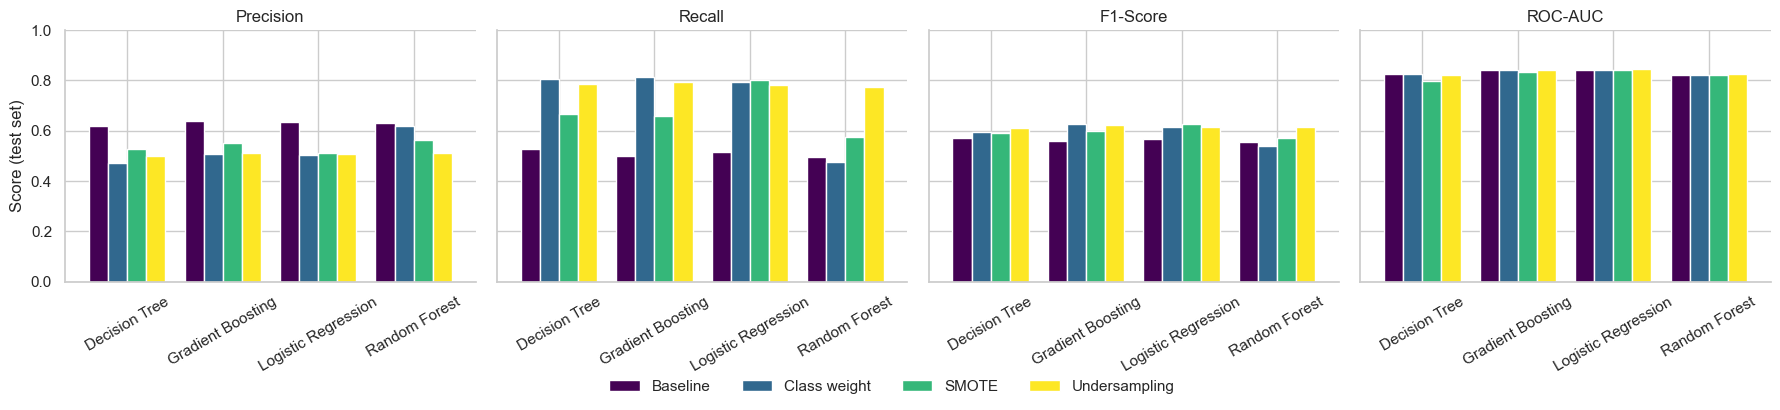

In [44]:
fig = plot_strategy_comparison(strategy_results)
save_fig(fig, "imbalance_strategies.png")
plt.show()

**What the experiment shows (test set)**

- **Every strategy raises recall a lot** for Logistic Regression (+0.27 to +0.29), Gradient Boosting (SMOTE +0.16, the other two +0.29 to +0.32) and Decision Tree (+0.14 to +0.28), going from about 50% to about **78-81% of churners detected**.
- The price is **precision**, which drops 9 to 15 points: more customers are flagged, and more of them would not have left. Accuracy falls from 79% to about 74%, which is expected and acceptable.
- **F1-score improves** (+0.02 to +0.06) and **ROC-AUC barely changes** (within 0.01, except Decision Tree + SMOTE, -0.03). This is logical: these methods do not make the model rank customers better, they only move the decision threshold towards the minority class.
- **Random Forest** does not benefit from class weights (its fully grown trees memorize the data, train ROC-AUC about 1.00), but undersampling raises its recall from 0.50 to 0.77. Its main problem is overfitting, which tuning addresses.
- **SMOTE is not better than simple class weights** and works worse with trees (it creates fractional values in binary columns such as `Contract`).

**Method selected: class weights.** It gets the same F1 as the other strategies, is the simplest, does not delete or invent data and trains faster. It is used from now on for tuning.

## 11. Hyperparameter Tuning

### 11.1 Cross-validation

A single train/test split can be lucky or unlucky. **Stratified 5-fold cross-validation** splits the training set into 5 parts, trains on 4 and validates on the remaining one, five times. If the score is similar in every fold, the model is **consistent**; a large spread means it is unstable. Only the training set is used, the test set stays untouched.

All four models are compared **without** and **with** class weights:

In [45]:
cv_baseline = cross_validate_models(build_models("Baseline", y_train), X_train, y_train)
cv_balanced = cross_validate_models(build_models("Class weight", y_train), X_train, y_train)
cv_baseline["Model"] += " (baseline)"
cv_balanced["Model"] += " (class weight)"
cv_results = pd.concat([cv_baseline, cv_balanced], ignore_index=True)

summarize_cv(cv_results)

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Model,,,,,
Logistic Regression (baseline),0.805 ± 0.009,0.666 ± 0.023,0.532 ± 0.031,0.591 ± 0.022,0.846 ± 0.013
Decision Tree (baseline),0.789 ± 0.005,0.617 ± 0.016,0.548 ± 0.063,0.578 ± 0.03,0.828 ± 0.011
Random Forest (baseline),0.792 ± 0.013,0.644 ± 0.039,0.486 ± 0.011,0.553 ± 0.02,0.824 ± 0.013
Gradient Boosting (baseline),0.8 ± 0.01,0.659 ± 0.036,0.511 ± 0.02,0.575 ± 0.015,0.846 ± 0.013
Logistic Regression (class weight),0.748 ± 0.013,0.517 ± 0.017,0.793 ± 0.035,0.626 ± 0.021,0.846 ± 0.012
Decision Tree (class weight),0.73 ± 0.026,0.497 ± 0.035,0.763 ± 0.049,0.6 ± 0.023,0.824 ± 0.009
Random Forest (class weight),0.79 ± 0.016,0.644 ± 0.047,0.469 ± 0.021,0.542 ± 0.028,0.824 ± 0.013
Gradient Boosting (class weight),0.749 ± 0.009,0.518 ± 0.012,0.791 ± 0.032,0.626 ± 0.016,0.845 ± 0.013


In [46]:
cv_results.pivot(index="Fold", columns="Model", values="F1-Score").round(3)

Model,Decision Tree (baseline),Decision Tree (class weight),Gradient Boosting (baseline),Gradient Boosting (class weight),Logistic Regression (baseline),Logistic Regression (class weight),Random Forest (baseline),Random Forest (class weight)
Fold,,,,,,,,
1,0.547,0.595,0.556,0.636,0.591,0.638,0.532,0.509
2,0.567,0.571,0.563,0.602,0.555,0.593,0.537,0.519
3,0.578,0.595,0.578,0.616,0.598,0.616,0.578,0.577
4,0.628,0.604,0.588,0.641,0.613,0.643,0.548,0.547
5,0.571,0.635,0.590,0.634,0.599,0.641,0.571,0.560


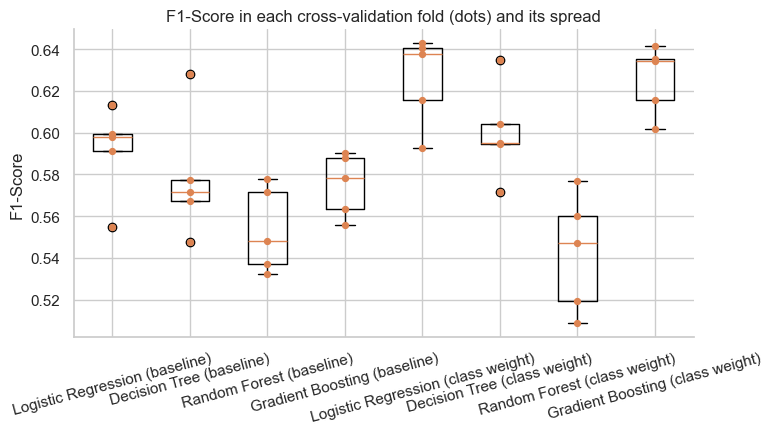

In [47]:
fig = plot_cv_scores(cv_results, "F1-Score")
save_fig(fig, "cross_validation_f1.png")
plt.show()

**Reading the cross-validation results**

- The standard deviation across folds is small (about 0.01 to 0.03 in F1 and ROC-AUC), so the models are **consistent**: the Week 3 results were not a lucky split.
- **Class weights raise recall in cross-validation too**, not only on the test set: from 0.53 to 0.79 (Logistic Regression), 0.51 to 0.79 (Gradient Boosting) and 0.55 to 0.76 (Decision Tree). The improvement is real and not a lucky split. Random Forest is the exception (0.49 to 0.47).
- Logistic Regression and Gradient Boosting with class weights are the most stable and best in F1 (about 0.63). The default Random Forest is the weakest and varies the most in precision, which signals overfitting.

### 11.2 Hyperparameter search

Each model is tuned **with class weights** using cross-validation on the training set, and the objective is the **F1-score**, which balances recall and precision.

| Model | Technique | What is searched |
|---|---|---|
| Logistic Regression | GridSearchCV | Regularization strength `C` |
| Decision Tree | GridSearchCV | Depth, minimum samples per leaf, split criterion |
| Random Forest | RandomizedSearchCV (25 combinations) | Trees, depth, minimum samples per leaf, features per split |
| Gradient Boosting / XGBoost | RandomizedSearchCV (25 combinations) | Trees, learning rate, depth, subsample |

In [48]:
searches = tune_all(X_train, y_train)
tuning_summary(searches)

Logistic Regression: best CV score 0.6304 (0s)


Decision Tree: best CV score 0.6222 (2s)


Random Forest: best CV score 0.6354 (25s)


Gradient Boosting: best CV score 0.6340 (32s)


,Best CV F1,Best parameters
Logistic Regression,0.6304,{'C': 0.01}
Decision Tree,0.6222,"{'criterion': 'gini', 'max_depth': 8, 'min_sam..."
Random Forest,0.6354,"{'max_depth': 12, 'max_features': 0.5, 'min_sa..."
Gradient Boosting,0.634,"{'learning_rate': 0.125, 'max_depth': 2, 'n_es..."


### 11.3 Default vs optimized models

In [49]:
tuned = {f"{name} (tuned)": search.best_estimator_ for name, search in searches.items()}
tuned_results = evaluate_models(tuned, X_train, y_train, X_test, y_test)

before = experiments["Class weight"]
default_vs_tuned = pd.concat(
    {
        "Class weight, default": compare_models(before),
        "Class weight, tuned": compare_models(tuned_results).rename(index=lambda n: n.replace(" (tuned)", "")),
    },
    names=["Version", "Model"],
).swaplevel().sort_index(level="Model", sort_remaining=False)
default_vs_tuned[["Precision", "Recall", "F1-Score", "ROC-AUC", "Train ROC-AUC"]].round(3)

Precision  Recall  F1-Score  \
Model               Version                                              
Decision Tree       Class weight, default      0.471   0.805     0.594   
                    Class weight, tuned        0.525   0.775     0.626   
Gradient Boosting   Class weight, default      0.508   0.813     0.625   
                    Class weight, tuned        0.500   0.802     0.616   
Logistic Regression Class weight, default      0.504   0.791     0.616   
                    Class weight, tuned        0.508   0.778     0.615   
Random Forest       Class weight, default      0.620   0.476     0.539   
                    Class weight, tuned        0.547   0.778     0.642   

                                           ROC-AUC  Train ROC-AUC  
Model               Version                                        
Decision Tree       Class weight, default    0.824          0.846  
                    Class weight, tuned      0.834          0.867  
Gradient Boosting   Class weight, default    0.840          0.882  
                    Class weight, tuned      0.842          0.870  
Logistic Regression Class weight, default    0.842          0.851  
                    Class weight, tuned      0.836          0.844  
Random Forest       Class weight, default    0.823          1.000  
                    Class weight, tuned      0.845          0.907

**Effect of tuning**

- **Random Forest improves the most**: F1 goes from 0.54 to **0.64** and recall from 0.48 to 0.78. Its overfitting also drops (train ROC-AUC from 1.00 to 0.91) because tuning limits depth and requires more samples per leaf.
- **Decision Tree** improves moderately (F1 0.59 to 0.63) when it is made shallower and more regularized.
- **Logistic Regression and Gradient Boosting barely change**: they were already close to their limit with default settings. The tiny drop on the test set is noise, since they improved or tied in cross-validation.
- The best settings were chosen on cross-validation only, so the test set was not used for tuning.

## 12. Final Model Selection

All versions are compared on the test set: the Week 3 baselines, the models with class weights and the tuned models.

In [50]:
all_models = pd.concat(
    [
        compare_models(experiments["Baseline"]).rename(index=lambda n: f"{n} | baseline"),
        compare_models(experiments["Class weight"]).rename(index=lambda n: f"{n} | class weight"),
        compare_models(tuned_results).rename(index=lambda n: n.replace(" (tuned)", " | tuned")),
    ]
)
final_table = all_models[METRICS].sort_values("F1-Score", ascending=False)
final_table.round(3).style.highlight_max(axis=0, color="#cfe8cf")

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Random Forest | tuned,0.770000,0.547000,0.778000,0.642000,0.845000
Decision Tree | tuned,0.754000,0.525000,0.775000,0.626000,0.834000
Gradient Boosting | class weight,0.741000,0.508000,0.813000,0.625000,0.840000
Logistic Regression | class weight,0.738000,0.504000,0.791000,0.616000,0.842000
Gradient Boosting | tuned,0.735000,0.500000,0.802000,0.616000,0.842000
Logistic Regression | tuned,0.741000,0.508000,0.778000,0.615000,0.836000
Decision Tree | class weight,0.708000,0.471000,0.805000,0.594000,0.824000
Decision Tree | baseline,0.789000,0.619000,0.527000,0.569000,0.827000
Logistic Regression | baseline,0.793000,0.636000,0.513000,0.568000,0.842000
Gradient Boosting | baseline,0.792000,0.639000,0.497000,0.559000,0.842000


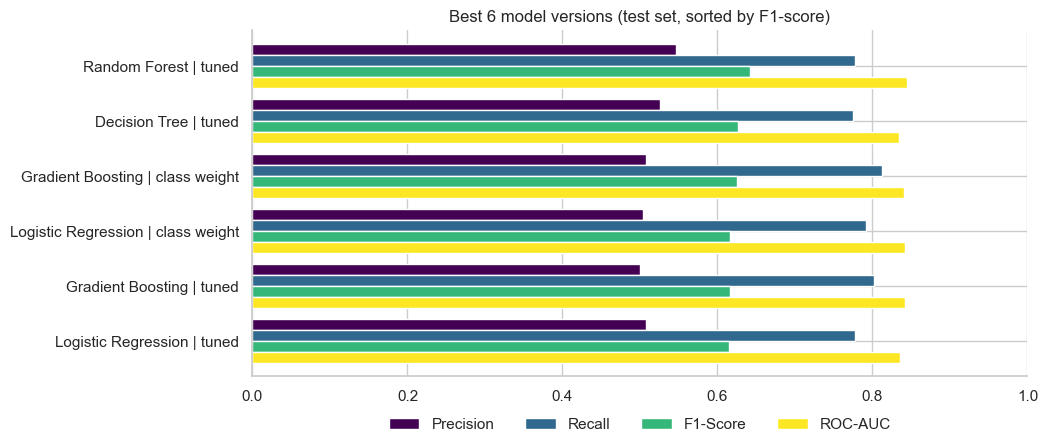

In [51]:
fig, ax = plt.subplots(figsize=(10, 4.5))
top = final_table.head(6)
top[["Precision", "Recall", "F1-Score", "ROC-AUC"]].plot(kind="barh", ax=ax, width=0.8, colormap="viridis")
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.set_title("Best 6 model versions (test set, sorted by F1-score)")
ax.legend(frameon=False, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.08))
ax.spines[["top", "right"]].set_visible(False)
save_fig(fig, "final_model_comparison.png")
plt.show()

### Final model decision

**Selected model: Random Forest (tuned, with class weights).**

| Criterion | Result |
|---|---|
| F1-score | **Best** of all versions (0.64) |
| ROC-AUC | Best (0.845), tied with the others within 0.01 |
| Recall | 0.78: detects about 4 of every 5 churners (the baseline detected 1 of 2) |
| Precision | 0.55: about half of the flagged customers really leave |
| Overfitting | Moderate (train ROC-AUC 0.91 vs 0.85 on test), much lower than the default forest (1.00) |
| Cross-validation | Best CV F1 in the search (0.635), stable across folds |

**Business usefulness.** Missing a churner means losing the customer's recurring revenue, while a false alarm only costs a retention offer or call. With recall going from 51% to 78%, the company can reach far more at-risk customers, and a precision of 55% is acceptable if the retention action is cheap (discount, courtesy call, contract upgrade).

**Honest limits of this choice**

- The differences between the best versions are small (F1 between 0.615 and 0.642), and with only 374 churners in the test set a gap of 0.02 is within the noise. Tuned Logistic Regression is a simpler, more interpretable alternative with almost the same ROC-AUC.
- The decision threshold is still the default 0.5. If the business prefers fewer false alarms or more coverage, it can be changed (a future improvement).

In Week 5 the selected model is interpreted with feature importance, and Logistic Regression coefficients are used as a second opinion.

In [52]:
FINAL_NAME = "Random Forest (tuned)"
final_model = tuned[FINAL_NAME]
final_pred = final_model.predict(X_test)
print(f"Final model: {FINAL_NAME}")
print(final_model.named_steps["model"])
confusion_matrix_table(y_test, final_pred)

Final model: Random Forest (tuned)
RandomForestClassifier(class_weight='balanced', max_depth=12, max_features=0.5,
                       min_samples_leaf=15, n_estimators=150, n_jobs=-1,
                       random_state=42)


,Predicted: No churn,Predicted: Churn
Actual: No churn,794,241
Actual: Churn,83,291


**Week 4 summary**

- Class imbalance analysed and 3 strategies compared before/after on Precision, Recall, F1 and ROC-AUC.
- 5-fold cross-validation to check consistency, and hyperparameter tuning with GridSearchCV and RandomizedSearchCV.
- Final model selected from baseline, balanced and tuned versions using technical and business criteria.

---
# Week 5: Interpretation, Business Insights and Final Conclusions

### 12.1 Final evaluation of the selected model

The selected model (tuned Random Forest with class weights) is evaluated one last time on the **test set**, which was never used to train or tune it.

In [53]:
from churn.features.preprocessing import NUMERIC_FEATURES
from churn.modeling.evaluate import compute_metrics
from churn.modeling.interpretation import (
    error_groups,
    impurity_importance_table,
    logistic_coefficients,
    permutation_importance_table,
    risk_deciles,
)
from churn.visualization.model_plots import plot_feature_importance, plot_risk_deciles

final_proba = final_model.predict_proba(X_test)[:, 1]
final_metrics = pd.Series(compute_metrics(y_test, final_pred, final_proba), name="Final model").round(3)
final_metrics.to_frame()

,Final model
Accuracy,0.770
Precision,0.547
Recall,0.778
F1-Score,0.642
ROC-AUC,0.845


**What each metric means for this model** (test set: 1,409 customers, 374 of them real churners)

| Metric | Value | Meaning in business terms |
|---|---|---|
| **Accuracy** | 0.770 | 77% of all customers are classified correctly. It looks lower than the baseline (79%), but only because the model now deliberately flags more customers. |
| **Precision** | 0.547 | The model flagged 532 customers as churners and 291 really left: about **1 of every 2 retention offers reaches someone who was leaving**. |
| **Recall** | 0.778 | Of the 374 customers who left, the model identified **291 (78%)**. The baseline found only 51%. |
| **F1-score** | 0.642 | Balance of the two previous metrics, the main score used to choose the model. |
| **ROC-AUC** | 0.845 | If we pick one churner and one non-churner at random, the model gives the churner the higher risk 84.5% of the time. |
| **Confusion matrix** | 291 TP, 83 FN, 241 FP, 794 TN | 83 churners are still missed (lost revenue) and 241 loyal customers would receive an unnecessary offer. |

## 13. Feature Importance

Two complementary techniques are used:

- **Permutation importance** (Random Forest): shuffles one feature at a time on the test set and measures how much the F1-score drops. A larger drop means the model relies more on that feature.
- **Logistic Regression coefficients**: show the *direction* (does it increase or decrease churn?). Numeric features are standardized, so the coefficients can be compared.

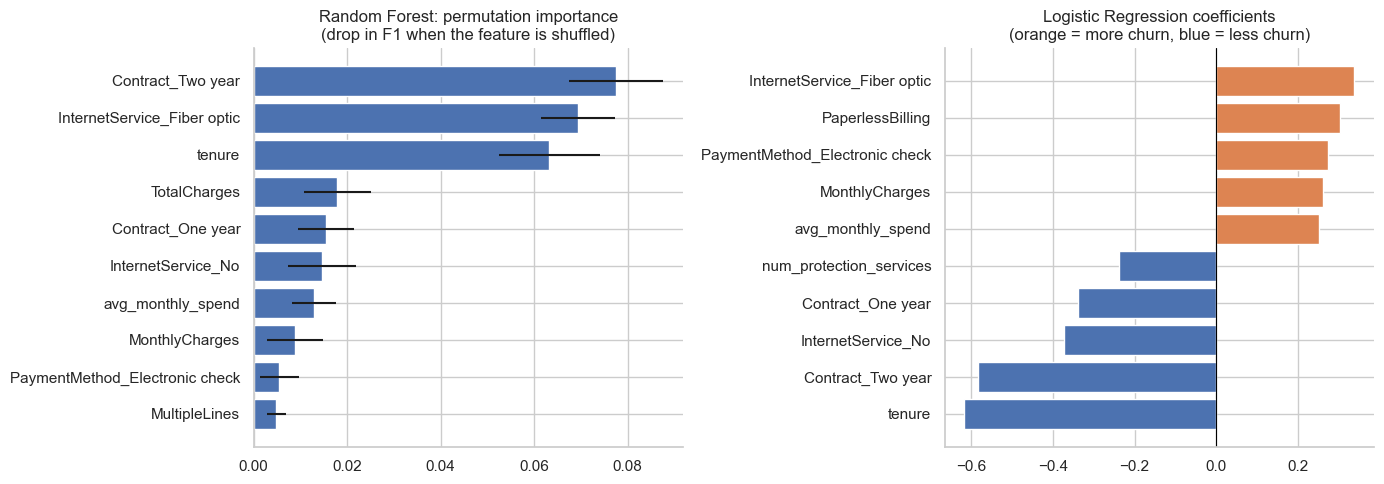

,importance,std
Contract_Two year,0.0775,0.0100
InternetService_Fiber optic,0.0693,0.0079
tenure,0.0632,0.0107
TotalCharges,0.0179,0.0072
Contract_One year,0.0154,0.0060
InternetService_No,0.0146,0.0072
avg_monthly_spend,0.0129,0.0047
MonthlyCharges,0.0089,0.0059
PaymentMethod_Electronic check,0.0055,0.0042
MultipleLines,0.0049,0.0020


In [54]:
perm = permutation_importance_table(final_model, X_test, y_test, scoring="f1")
lr_model = tuned["Logistic Regression (tuned)"]
coefficients = logistic_coefficients(lr_model, X_test.columns, NUMERIC_FEATURES)

fig = plot_feature_importance(perm, coefficients)
save_fig(fig, "feature_importance.png")
plt.show()
perm.head(10).round(4)

In [55]:
impurity_importance_table(final_model.named_steps["model"], X_test.columns).head(10).round(3).to_frame("built-in importance")

,built-in importance
Contract_Two year,0.191
tenure,0.171
InternetService_Fiber optic,0.114
TotalCharges,0.100
MonthlyCharges,0.076
Contract_One year,0.074
avg_monthly_spend,0.068
PaymentMethod_Electronic check,0.045
InternetService_No,0.025
num_protection_services,0.018


**Strongest predictors of churn**

1. **Contract type** (two-year contract): the most important feature. Longer contracts protect strongly against churn (coefficients for one and two-year contracts are both negative).
2. **Fiber optic internet**: the second most important feature and the strongest factor *towards* churn in the Logistic Regression.
3. **Tenure**: the longer the customer has stayed, the lower the risk. It is the most negative coefficient.
4. Next: `TotalCharges`, having no internet service (low risk), `avg_monthly_spend`, `MonthlyCharges` and **electronic check** payment (higher risk).
5. Services that **reduce** churn: `num_protection_services` and `OnlineSecurity`. Factors that **increase** it: paperless billing, electronic check, higher monthly charges and being a senior citizen.

Both techniques agree, and they also agree with the EDA of Week 2. The engineered features helped moderately: `avg_monthly_spend` and `num_protection_services` rank in the top 12.

> These are **associations**, not proven causes: for example, fiber customers may churn because of price, quality or competition, and the data cannot tell which.

## 14. Business Insights

### 14.1 Model errors: false positives and false negatives

- **False positive (FP):** the model predicted churn, but the customer stayed. Business cost: a retention offer (discount, call) that was not needed.
- **False negative (FN):** the model predicted the customer stays, but they left. Business cost: lost recurring revenue and no chance to react. It is usually the more expensive error.

In [56]:
features_test = pd.read_csv(FEATURES_DATA_PATH).loc[X_test.index].copy()
features_test["group"] = error_groups(y_test, pd.Series(final_pred, index=y_test.index))

profile = features_test.groupby("group")[["tenure", "MonthlyCharges", "num_protection_services"]].mean().round(1)
profile["share_month_to_month_%"] = features_test.groupby("group")["Contract"].apply(lambda s: (s == "Month-to-month").mean() * 100).round(0)
profile["share_fiber_%"] = features_test.groupby("group")["InternetService"].apply(lambda s: (s == "Fiber optic").mean() * 100).round(0)
profile["share_electronic_check_%"] = features_test.groupby("group")["PaymentMethod"].apply(lambda s: (s == "Electronic check").mean() * 100).round(0)
profile.insert(0, "customers", features_test["group"].value_counts())
profile.loc[["TP", "FP", "FN", "TN"]]

,customers,tenure,MonthlyCharges,num_protection_services,share_month_to_month_%,share_fiber_%,share_electronic_check_%
group,,,,,,,
TP,291,11.6,74.3,0.7,98.0,76.0,63.0
FP,241,17.4,73.5,0.8,96.0,71.0,56.0
FN,83,33.4,67.3,1.5,52.0,39.0,28.0
TN,794,43.6,57.2,1.5,27.0,24.0,17.0


**TP** = correctly detected churners, **FP** = false alarms, **FN** = missed churners, **TN** = correctly identified loyal customers.

- **False positives (241)** look exactly like typical churners: short tenure (17 months on average), month-to-month contract (96%), fiber optic (71%) and electronic check (56%). They are *at-risk customers who happened to stay*, so contacting them is not a waste: they are the group where a retention offer is most useful.
- **False negatives (83)** look like loyal customers: tenure of 33 months on average, only 52% month-to-month and 37% on one-year contracts, and as many protection services as loyal customers (1.5 on average). They churn for reasons **that are not in this dataset** (a competitor's offer, poor service experience, moving, life changes). Detecting them would need data such as complaints, support calls, usage or satisfaction surveys.

### 14.2 Using the model to prioritize customers

Ranking customers by predicted risk shows how well the company could focus its retention budget:

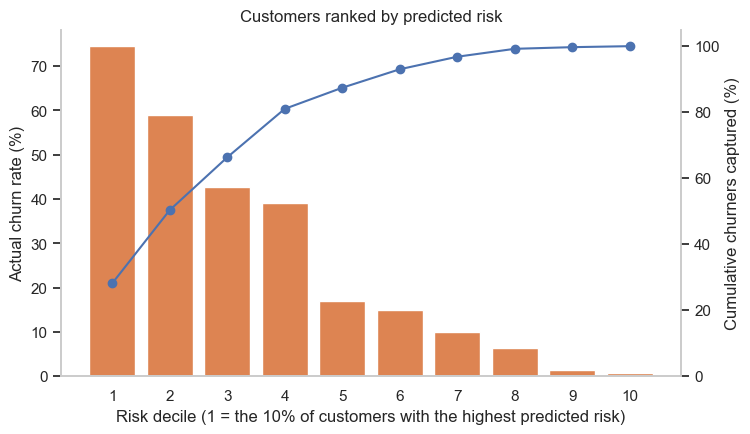

,customers,churners,churn_rate_%,cumulative_churners_captured_%
decile,,,,
1,141,105,74.5,28.1
2,141,83,58.9,50.3
3,141,60,42.6,66.3
4,141,55,39.0,81.0
5,141,24,17.0,87.4
6,140,21,15.0,93.0
7,141,14,9.9,96.8
8,141,9,6.4,99.2
9,141,2,1.4,99.7


In [57]:
deciles = risk_deciles(y_test, final_proba)
fig = plot_risk_deciles(deciles)
save_fig(fig, "risk_deciles.png")
plt.show()
deciles

- The **10% of customers with the highest risk churn 74.5%** of the time, versus the 26.5% average.
- Contacting only the **top 20%** of customers reaches **50% of all churners**, and the **top 40% reaches 81%**.
- The bottom 30% of customers (deciles 8 to 10) almost never churn (below 7%), so they need no retention effort.

This turns the model into a practical tool: a monthly ranked list of at-risk customers instead of contacting everybody.

## 15. Recommendations

Every recommendation is based on findings of this analysis.

1. **Move month-to-month customers to longer contracts.** Contract type is the top predictor: month-to-month customers churn 42.7%, versus 11.3% with one year and 2.8% with two years. Offer a discount, a free add-on or a price lock for committing to 12 or 24 months, especially after the first months.
2. **Create a strong onboarding program for the first year.** 47.4% of customers with up to 12 months churn, and correctly detected churners have a mean tenure of only 12 months. Proactive contact in months 1 to 3, a welcome offer and a check-in before the first anniversary can reduce early churn.
3. **Investigate and improve the fiber optic offer.** Fiber customers churn 41.9% (DSL 19.0%) and it is the strongest churn factor in the model. Review price against competitors and service quality, and bundle fiber with security or support services.
4. **Encourage automatic payment.** Electronic check users churn 45.3%, against 15-17% for automatic bank transfer or credit card. A small discount for switching to automatic payment also removes a monthly friction point.
5. **Promote security and tech support add-ons.** Customers with Online Security or Tech Support churn about 15%, versus about 31% without them, and with all four protection services churn falls to 5.3%. Offer them free for a trial period to customers with none.
6. **Run targeted retention campaigns with the risk ranking.** The top 20% highest-risk customers include 50% of churners, and the top 40% include 81%. Concentrate calls and offers on those groups, and skip the lowest-risk 30%.
7. **Design a loyalty program for vulnerable segments.** Senior citizens (41.7%), customers without partner (33.0%) or without dependents (31.3%) churn more. Dedicated support lines or family/shared plans may help.
8. **Collect richer data to find the missed churners.** The 83 undetected churners look loyal in the current data. Complaints, support calls, usage and satisfaction scores would let the model detect them.

## 16. Conclusion

### Summary
- The dataset has 7,043 customers with a 26.5% churn rate. After cleaning it and creating 7 new features, four classification models were trained and compared.
- The baseline models reached ~79% accuracy but caught only half of the churners. **Class weights** and **hyperparameter tuning** raised recall from 51% to **78%** and F1 from 0.57 to **0.64**, with a ROC-AUC of **0.845**.
- The **final model is a tuned Random Forest with class weights**. The main churn drivers are contract type, fiber optic internet, tenure, payment method and the lack of protection services.

### Limitations
- **Not causal:** the model finds associations; it does not prove why customers leave.
- **Precision of 55%:** about half of the flagged customers would have stayed, so retention actions must be cheap.
- **83 churners are still missed**, and they look loyal in the data. Important behavior variables (usage, complaints, satisfaction) are missing.
- **Single snapshot and small test set:** 374 churners in the test set, so small differences between models are within the noise, and customer behavior may change over time.
- **Public sample dataset:** results may not transfer directly to another company.
- XGBoost could not be used on the development machine, so sklearn's Gradient Boosting was used instead.

### Future improvements
- Adjust the **decision threshold** to the real cost of a retention offer versus a lost customer.
- Try **XGBoost / LightGBM** (with `libomp` installed) and calibrate the predicted probabilities.
- Add behavioral data and test **SMOTENC**, which handles categorical features better than plain SMOTE.
- Use **SHAP values** for explanations at the individual customer level.
- Monitor the model over time and retrain it, and run an A/B test of the retention actions to measure their real effect.

---
_End of the project. The final presentation outline is in `docs/presentation.md`._